<h1 id="Search-in-Complex-Environments">Search in Complex Environments</h1><p>Let's see visual demonstrations of the three search families:</p>
<ol>
<li><strong>Search — local search</strong> (AIMA §4.1): Hill climbing &amp; simulated annealing</li>
<li><strong>Continuous search</strong> (AIMA §4.2, Murphy §8.3): Gradient descent &amp; <strong>potential fields</strong> for robot navigation</li>
<li><strong>A* and online search</strong> (AIMA §4.5): A* on a known map vs. <strong>LRTA*</strong> real-time search on an unknown map</li>
</ol>
<p>The thread tying it together: a reactive robot rarely has the whole map or a smooth global objective. It must act from local information. Each method below is a different answer to "How do I make progress when I can only see what is around me?" — and each has a characteristic failure mode (getting stuck in a local optimum) that motivates the next.</p>


In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 72
import numpy as np
import os
import heapq  # heap DS

plt.rcParams.update({'figure.figsize':(7, 4.2), 'axes.grid':True, 'grid.alpha':0.3, 'font.size':11})

Randg = np.random.default_rng(4)   # fixed seed for reproducible runs



<h2 id="Local-Search">Local Search</h2><p>Sometimes we care only about the <strong>final state</strong>, not the path to it (8-queens, circuit layout, scheduling problems). A <strong>local search</strong> agent keeps a single current state and repeatedly moves to a neighbor, using almost no memory.</p>
<p>Picture a <strong>state-space landscape</strong>: every state has an elevation = value of the objective function. Hill climbing tries to find the highest peak — the <strong>global maximum</strong> — but can stall on a <strong>local maximum</strong>, a <strong>ridge</strong>, or a flat <strong>plateau</strong>.</p>


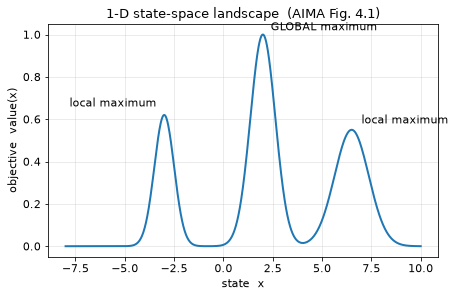

In [2]:
# A 1-D state-space landscape we want to MAXIMISE ("elevation")
def landscape(x):
    return (1.00*np.exp(-(x-2.0)**2/0.8)  # GLOBAL max near x=2
        + 0.62*np.exp(-(x+3.0)**2/0.5)    # local  max near x=-3
        + 0.55*np.exp(-(x-6.5)**2/1.5))   # local  max near x=6.5

xs = np.linspace(-8, 10, 800); ys = landscape(xs)

plt.figure()
plt.plot(xs, ys, lw=2)
plt.annotate('GLOBAL maximum', (2, 1.0), (2.4, 1.02))
plt.annotate('local maximum', (-3, 0.62), (-7.8, 0.66))
plt.annotate('local maximum', (6.5, 0.55), (7.0, 0.58))
plt.title('1-D state-space landscape  (AIMA Fig. 4.1)')
plt.xlabel('state  x'); plt.ylabel('objective  value(x)'); plt.show()



<h3 id="%F0%9F%94%B8-Hill-Climbing-(Steepest-Ascent)">🔸 Hill Climbing (Steepest Ascent)</h3><pre><code>function HILL-CLIMBING(problem) returns a local maximum
    current &lt;- problem.INITIAL
    while true:
        neighbor &lt;- highest-valued successor of current
        if VALUE(neighbor) &lt;= VALUE(current): return current
        current &lt;- neighbor
</code></pre>
<p>(AIMA Fig. 4.2)  It only ever moves uphill, so where it ends up depends entirely on <strong>where it start</strong>.</p>


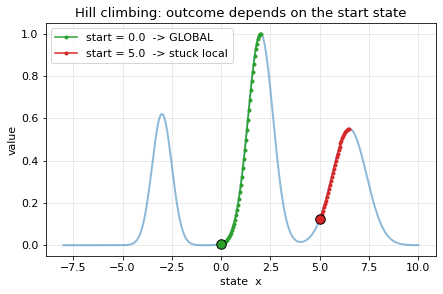

from 0.0 -> x=2.00  value=1.000
from 5.0 -> x=6.50  value=0.550  (LOCAL optimum)


In [3]:
def hill_climb(start, step=0.05, lo=-8, hi=10):
    x, path = start, [start]
    while True:
        cands = [c for c in (x-step, x+step) if lo <= c <= hi]
        best = max(cands, key=landscape) if cands else x
        if landscape(best) <= landscape(x):     # no uphill neighbor -> stop
            break
        x = best; path.append(x)
    return np.array(path)

p_good = hill_climb(0.0)  # starts in the global basin
p_bad  = hill_climb(5.0)  # starts in a local basin -> gets stuck

plt.figure()
plt.plot(xs, ys, lw=2, alpha=0.5)
for p, c, lbl in [(p_good,'C2','start = 0.0  -> GLOBAL'), (p_bad,'C3','start = 5.0  -> stuck local')]:
    plt.plot(p, landscape(p), 'o-', color=c, ms=3, label=lbl)
    plt.scatter(p[0], landscape(p[0]), color=c, s=90, zorder=5, edgecolor='k')
plt.legend(); plt.title('Hill climbing: outcome depends on the start state')
plt.xlabel('state  x'); plt.ylabel('value'); plt.show()

print(f"from 0.0 -> x={p_good[-1]:.2f}  value={landscape(p_good[-1]):.3f}")
print(f"from 5.0 -> x={p_bad[-1]:.2f}  value={landscape(p_bad[-1]):.3f}  (LOCAL optimum)")


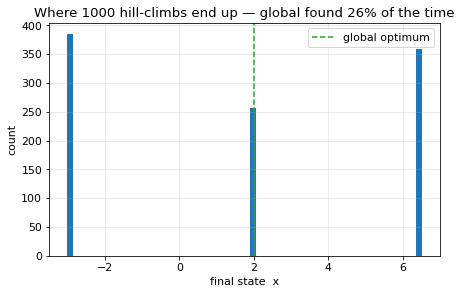

In [4]:
# How often does plain hill climbing find the GLOBAL optimum, from random starts?
starts = Randg.uniform(-8, 10, 1000)
ends   = np.array([hill_climb(s)[-1] for s in starts])
global_rate = np.mean(np.abs(ends - 2.0) < 0.3)

plt.figure()
plt.hist(ends, bins=60)
plt.axvline(2.0, color='C2', ls='--', label='global optimum')
plt.title(f"Where 1000 hill-climbs end up — global found {100*global_rate:.0f}% of the time")
plt.xlabel('final state  x'); plt.ylabel('count'); plt.legend(); plt.show()



<h3 id="%F0%9F%94%B8-Simulated-Annealing">🔸 Simulated Annealing</h3><p>Pure hill climbing never goes downhill, so it cannot escape a local maximum. <strong>Simulated annealing</strong> mixes hill climbing with a random walk: it proposes a random move and</p>
<ul>
<li><strong>Always</strong> accepts an improving move, and</li>
<li>Accepts a worsening move with probability $e^{\Delta E / T}$  (the Boltzmann factor),</li>
</ul>
<p>where $\Delta E&lt;0$ is how much worse the move is and $T$ is a <strong>temperature</strong> lowered on a cooling <strong>schedule</strong>. Early on (high $T$) it wanders freely and can climb out of local optima; as $T\to0$ it behaves like hill climbing and settles. (AIMA Fig. 4.5)</p>


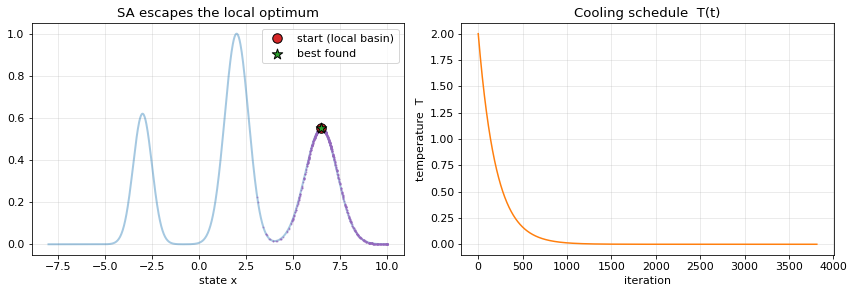

SA started at x=6.5 (local), ended near x=6.50  value=0.550


In [5]:
def simulated_annealing(start, T0=2.0, alpha=0.995, n=4000, prop_sd=0.7, lo=-8, hi=10):
    x, best, path, T = start, start, [start], T0
    temps, accepted = [], []
    for _ in range(n):
        if T < 1e-8: break
        nxt = np.clip(x + Randg.normal(0, prop_sd), lo, hi)
        dE  = landscape(nxt) - landscape(x)          # >0 means improvement
        if dE > 0 or Randg.random() < np.exp(dE / T):  # Boltzmann acceptance
            x = nxt; accepted.append(True)
            if landscape(x) > landscape(best): best = x
        else:
            accepted.append(False)
        path.append(x); temps.append(T); T *= alpha  # geometric cooling
    return best, np.array(path), np.array(temps)

best, sa_path, temps = simulated_annealing(6.5)  # start trapped in the local basin

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(xs, ys, lw=2, alpha=0.4)
ax[0].plot(sa_path, landscape(sa_path), '.', ms=2, color='C4', alpha=0.5)
ax[0].scatter(6.5, landscape(6.5), s=90, color='C3', edgecolor='k', zorder=5, label='start (local basin)')
ax[0].scatter(best, landscape(best), s=120, marker='*', color='C2', edgecolor='k', zorder=5, label='best found')
ax[0].set_title('SA escapes the local optimum'); ax[0].legend(); ax[0].set_xlabel('state x')
ax[1].plot(temps, color='C1'); ax[1].set_title('Cooling schedule  T(t)')
ax[1].set_xlabel('iteration'); ax[1].set_ylabel('temperature  T')
plt.tight_layout(); plt.show()
print(f"SA started at x=6.5 (local), ended near x={best:.2f}  value={landscape(best):.3f}")


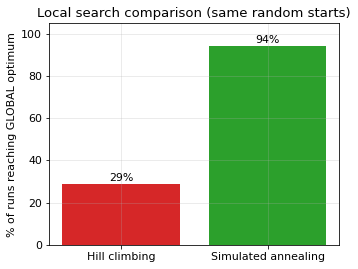

In [6]:
# Head-to-head success rate (fraction reaching the GLOBAL optimum) from random starts
N = 300; s = Randg.uniform(-8, 10, N)
hc = np.mean([abs(hill_climb(v)[-1]            - 2.0) < 0.3 for v in s])
sa = np.mean([abs(simulated_annealing(v)[0]    - 2.0) < 0.3 for v in s])

plt.figure(figsize=(5.2,4))
plt.bar(['Hill climbing','Simulated annealing'], [100*hc, 100*sa], color=['C3','C2'])
for i,v in enumerate([hc,sa]): plt.text(i, 100*v+1.5, f"{100*v:.0f}%", ha='center')
plt.ylabel('% of runs reaching GLOBAL optimum'); plt.ylim(0,105)
plt.title('Local search comparison (same random starts)'); plt.show()


## Assignment 4 - 1. Annealing

This section measures the hill-climbing baseline, tests random restarts, and compares restarts with simulated annealing under an equal objective-evaluation budget.  The dedicated RNG makes the stochastic results reproducible.

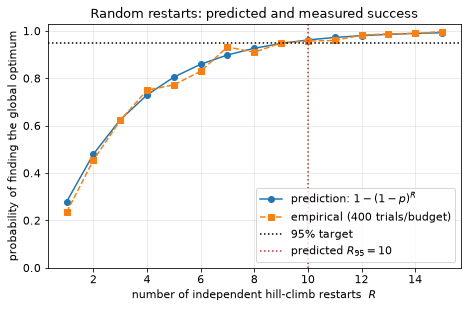

Per-run hill-climb success p = 0.279; predicted R_95 = 10 restarts.
Empirical success at R_95 = 0.958.


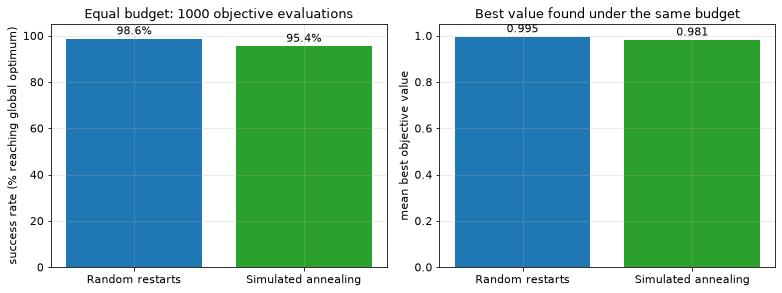

Random restarts: success=0.986, mean best value=0.995, mean evaluations used=999.5, mean restarts=14.9
Simulated annealing: success=0.954, mean best value=0.981, mean evaluations used=1000


In [3]:
# Assignment 4, Question 1: random restarts and a fair SA comparison
# Count every call to landscape() as one objective-function evaluation.
Q1_RNG = np.random.default_rng(2026)
GLOBAL_X, SUCCESS_TOL = 2.0, 0.30

def is_global(x):
    return abs(x - GLOBAL_X) < SUCCESS_TOL

def hill_climb_counted(start, eval_budget=np.inf, step=0.05, lo=-8, hi=10):
    """Steepest-ascent hill climb, returning its best point and evaluation count."""
    x = float(start)
    value = landscape(x); evaluations = 1
    best_x, best_value = x, value
    while evaluations + 2 <= eval_budget:
        candidates = [x-step, x+step]
        candidate_values = [landscape(c) for c in candidates]
        evaluations += 2
        j = int(np.argmax(candidate_values))
        if candidate_values[j] <= value:
            break
        x, value = candidates[j], candidate_values[j]
        if value > best_value:
            best_x, best_value = x, value
    return best_x, best_value, evaluations

def random_restart(n_restarts, rng):
    best_x, best_value = None, -np.inf
    for _ in range(n_restarts):
        x, value, _ = hill_climb_counted(rng.uniform(-8, 10))
        if value > best_value:
            best_x, best_value = x, value
    return best_x, best_value

def random_restart_budget(eval_budget, rng):
    """Use restarts until an objective-evaluation budget is exhausted."""
    used = runs = 0; best_x, best_value = None, -np.inf
    while used + 3 <= eval_budget:  # one start evaluation and at least one comparison
        x, value, cost = hill_climb_counted(rng.uniform(-8, 10), eval_budget-used)
        used += cost; runs += 1
        if value > best_value:
            best_x, best_value = x, value
    return best_x, best_value, used, runs

def simulated_annealing_counted(start, eval_budget, rng,
                                T0=2.0, alpha=0.995, prop_sd=0.7,
                                lo=-8, hi=10):
    """SA using the same accounting: one evaluation for the start and each proposal."""
    x = float(start); value = landscape(x); evaluations = 1
    best_x, best_value, T = x, value, T0
    while evaluations < eval_budget and T >= 1e-8:
        proposal = np.clip(x + rng.normal(0, prop_sd), lo, hi)
        proposal_value = landscape(proposal); evaluations += 1
        dE = proposal_value - value
        if dE > 0 or rng.random() < np.exp(dE / T):
            x, value = proposal, proposal_value
        if value > best_value:
            best_x, best_value = x, value
        T *= alpha
    return best_x, best_value, evaluations

# (a) Estimate per-run p and the restart count needed for 95% success.
N_BASELINE = 1000
baseline_starts = Q1_RNG.uniform(-8, 10, N_BASELINE)
baseline = [hill_climb_counted(s) for s in baseline_starts]
p_hat = np.mean([is_global(x) for x, _, _ in baseline])
r_95 = int(np.ceil(np.log(1 - 0.95) / np.log(1 - p_hat)))

restart_budgets = np.arange(1, 16)
N_RESTART_TRIALS = 400
empirical_success = []
for budget in restart_budgets:
    successes = [is_global(random_restart(budget, Q1_RNG)[0])
                 for _ in range(N_RESTART_TRIALS)]
    empirical_success.append(np.mean(successes))
empirical_success = np.array(empirical_success)
predicted_success = 1 - (1-p_hat)**restart_budgets

plt.figure(figsize=(7.4, 4.4))
plt.plot(restart_budgets, predicted_success, 'o-', label=r'prediction: $1-(1-p)^{R}$')
plt.plot(restart_budgets, empirical_success, 's--', label=f'empirical ({N_RESTART_TRIALS} trials/budget)')
plt.axhline(0.95, color='k', ls=':', label='95% target')
plt.axvline(r_95, color='C3', ls=':', label=f'predicted $R_{{95}}={r_95}$')
plt.xlabel('number of independent hill-climb restarts  $R$')
plt.ylabel('probability of finding the global optimum')
plt.ylim(0, 1.03); plt.legend(); plt.title('Random restarts: predicted and measured success')
plt.show()
print(f'Per-run hill-climb success p = {p_hat:.3f}; predicted R_95 = {r_95} restarts.')
print(f'Empirical success at R_95 = {empirical_success[r_95-1]:.3f}.')

# (b) Equal budget: each method receives exactly 1,000 objective evaluations per trial.
EVAL_BUDGET, N_FAIR_TRIALS = 1000, 500
restart_results, sa_results, restart_evals, restart_runs = [], [], [], []
for _ in range(N_FAIR_TRIALS):
    x_rr, value_rr, used_rr, runs_rr = random_restart_budget(EVAL_BUDGET, Q1_RNG)
    x_sa, value_sa, used_sa = simulated_annealing_counted(
        Q1_RNG.uniform(-8, 10), EVAL_BUDGET, Q1_RNG)
    restart_results.append((x_rr, value_rr))
    sa_results.append((x_sa, value_sa))
    restart_evals.append(used_rr); restart_runs.append(runs_rr)

methods = ['Random restarts', 'Simulated annealing']
success_rates = [np.mean([is_global(x) for x, _ in restart_results]),
                 np.mean([is_global(x) for x, _ in sa_results])]
mean_best_values = [np.mean([value for _, value in restart_results]),
                    np.mean([value for _, value in sa_results])]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].bar(methods, 100*np.array(success_rates), color=['C0', 'C2'])
ax[0].set_ylabel('success rate (% reaching global optimum)'); ax[0].set_ylim(0, 105)
ax[0].set_title(f'Equal budget: {EVAL_BUDGET} objective evaluations')
for i, rate in enumerate(success_rates):
    ax[0].text(i, 100*rate + 2, f'{100*rate:.1f}%', ha='center')
ax[1].bar(methods, mean_best_values, color=['C0', 'C2'])
ax[1].set_ylabel('mean best objective value'); ax[1].set_ylim(0, 1.05)
ax[1].set_title('Best value found under the same budget')
for i, value in enumerate(mean_best_values):
    ax[1].text(i, value + .02, f'{value:.3f}', ha='center')
plt.tight_layout(); plt.show()

print(f'Random restarts: success={success_rates[0]:.3f}, mean best value={mean_best_values[0]:.3f}, '
      f'mean evaluations used={np.mean(restart_evals):.1f}, mean restarts={np.mean(restart_runs):.1f}')
print(f'Simulated annealing: success={success_rates[1]:.3f}, mean best value={mean_best_values[1]:.3f}, '
      f'mean evaluations used={EVAL_BUDGET:.0f}')

a) 


<hr/>
<h2 id="Continuous-Search-&amp;-Potential-Fields">Continuous Search &amp; Potential Fields</h2><p>Real robots live in <strong>continuous</strong> space, which has an infinite branching factor — we cannot enumerate "neighbors." Instead we follow the <strong>gradient</strong> of the objective. AIMA calls this local search in continuous spaces; in robotics it appears as the <strong>potential field</strong> method (Murphy Ch. 8).</p>



<h3 id="%F0%9F%94%B8-Gradient-Descent-in-a-Continuous-Space">🔸 Gradient Descent in a Continuous Space</h3><p>To <strong>minimise</strong> $f(\mathbf{x})$ we step opposite the gradient: $\;\mathbf{x} \leftarrow \mathbf{x} - \eta\,\nabla f(\mathbf{x})$.
We use Himmelblau's function (four equal minima) to show that, like hill climbing, gradient descent converges to <strong>whichever basin you start in</strong>.</p>


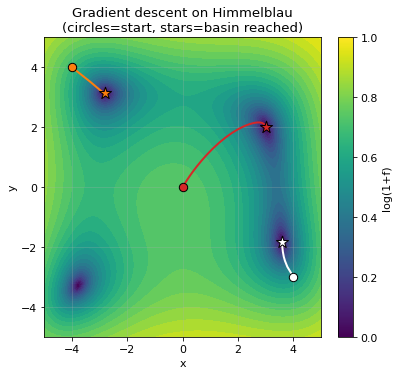

In [8]:
def himmel(p):
    x, y = p; return (x**2 + y - 11)**2 + (x + y**2 - 7)**2
def himmel_grad(p):
    x, y = p
    return np.array([4*x*(x**2+y-11) + 2*(x+y**2-7),
                     2*(x**2+y-11) + 4*y*(x+y**2-7)])
def grad_descent(p0, lr=0.005, n=400):
    p = np.array(p0, float); traj=[p.copy()]
    for _ in range(n): p = p - lr*himmel_grad(p); traj.append(p.copy())
    return np.array(traj)

gx, gy = np.meshgrid(np.linspace(-5,5,300), np.linspace(-5,5,300))
Z = (gx**2 + gy - 11)**2 + (gx + gy**2 - 7)**2

plt.figure(figsize=(6.2,5.4))
plt.contourf(gx, gy, np.log1p(Z), levels=30, cmap='viridis')
for p0, c in [([0,0],'C3'), ([-4,4],'C1'), ([4,-3],'w')]:
    t = grad_descent(p0)
    plt.plot(t[:,0], t[:,1], '-', color=c, lw=2)
    plt.scatter(*p0, color=c, edgecolor='k', s=70, zorder=5)
    plt.scatter(*t[-1], color=c, marker='*', edgecolor='k', s=160, zorder=5)
plt.title('Gradient descent on Himmelblau\n(circles=start, stars=basin reached)')
plt.xlabel('x'); plt.ylabel('y'); plt.colorbar(label='log(1+f)'); plt.show()



<h3 id="%F0%9F%94%B8-Potential-Fields-for-Robot-Navigation">🔸 Potential Fields for Robot Navigation</h3><p>Murphy describes navigation as a robot-shaped <strong>marble rolling on a potential-energy surface</strong> built from primitive fields. The two we need:</p>
<ul>
<li>An <strong>attractive</strong> field that pulls the robot toward the <strong>goal</strong>, and</li>
<li>A <strong>repulsive</strong> field around each <strong>obstacle</strong> (strength grows as the robot gets closer — a magnitude profile).</li>
</ul>
<p>The robot only ever computes the <strong>resultant vector at its own location</strong> and steps along it — this is gradient descent on the summed potential. No global plan, pure reaction.</p>


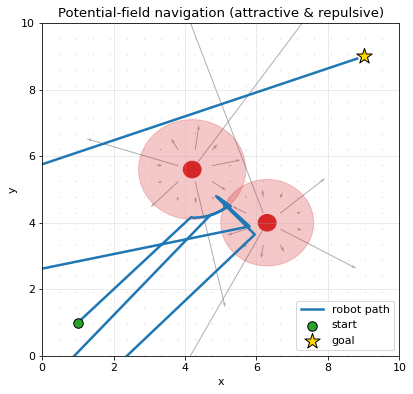

In [9]:
GOAL = np.array([9.0, 9.0])
K_ATT, K_REP, VMAX = 1.0, 120.0, 2.0
OBST = [ (np.array([4.2, 5.6]), 1.5), (np.array([6.3, 4.0]), 1.3) ]  # (centre, influence radius)

def force(p, obstacles, tangential=0.0):
    f = -K_ATT*(p - GOAL)                                   # attractive -> goal
    nrm = np.linalg.norm(f)
    if nrm > VMAX: f = f/nrm*VMAX                           # cap approach speed
    for c, rho0 in obstacles:
        d = p - c; rho = np.linalg.norm(d)
        if 1e-6 < rho <= rho0:                              # only within influence radius
            f = f + K_REP*(1.0/rho - 1.0/rho0)/(rho**2) * (d/rho)      # repulsive
            if tangential:                                             # Murphy tangential primitive
                f = f + tangential*np.array([-d[1], d[0]])/rho
    return f

def navigate(start, obstacles, tangential=0.0, n=1500, dt=0.05):
    p = np.array(start, float); path=[p.copy()]
    for _ in range(n):
        p = p + dt*force(p, obstacles, tangential); path.append(p.copy())
        if np.linalg.norm(p-GOAL) < 0.2: break
    return np.array(path)

# quiver of the resultant field + the robot's reactive path
gx, gy = np.meshgrid(np.linspace(0,10,22), np.linspace(0,10,22))
U = np.zeros_like(gx); V = np.zeros_like(gy)
for i in range(gx.shape[0]):
    for j in range(gx.shape[1]):
        f = force(np.array([gx[i,j], gy[i,j]]), OBST); U[i,j], V[i,j] = f
path = navigate([1.0, 1.0], OBST)

plt.figure(figsize=(6.4,6))
plt.quiver(gx, gy, U, V, color='0.6', alpha=0.8)
for c, rho0 in OBST:
    plt.gca().add_patch(plt.Circle(c, rho0, color='C3', alpha=0.25))
    plt.gca().add_patch(plt.Circle(c, 0.25, color='C3'))
plt.plot(path[:,0], path[:,1], 'C0-', lw=2.5, label='robot path')
plt.scatter(1,1, c='C2', s=90, edgecolor='k', zorder=5, label='start')
plt.scatter(*GOAL, c='gold', marker='*', s=260, edgecolor='k', zorder=5, label='goal')
plt.legend(loc='lower right'); plt.title('Potential-field navigation (attractive & repulsive)')
plt.xlim(0,10); plt.ylim(0,10); plt.xlabel('x'); plt.ylabel('y'); plt.show()



<h3 id="%F0%9F%94%B8-The-Local-minimum-Trap-%E2%80%94-and-a-Fix">🔸 The Local-minimum Trap — and a Fix</h3><p>Potential fields share hill climbing's weakness: a robot can reach a point where the attractive and repulsive forces <strong>exactly cancel</strong> and stall before the goal — a <strong>local minimum</strong>. It is easy to provoke: put an obstacle squarely on the straight line between start and goal.</p>
<p>A classic fix is Murphy's <strong>tangential</strong> primitive: add a sideways "swirl" around obstacles so the robot slides around instead of pressing straight into the dead spot. (Note the parallel to simulated annealing — both inject a non-greedy component to escape a basin.)</p>


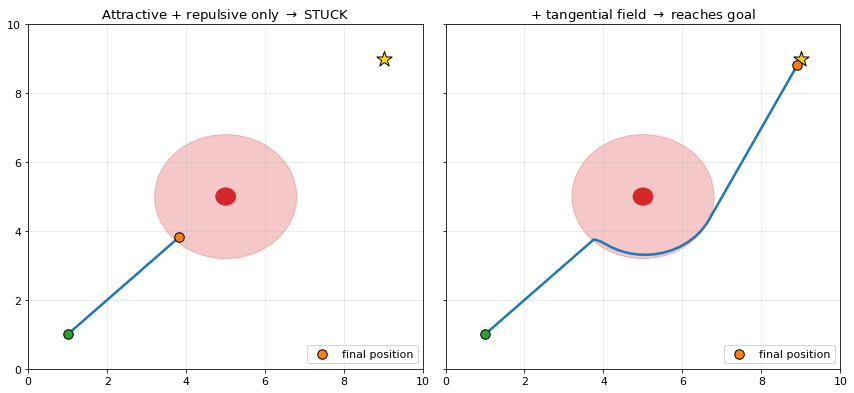

plain      -> final [3.82 3.82] | reached goal: False
tangential -> final [8.91 8.82] | reached goal: True


In [10]:
TRAP = [ (np.array([5.0, 5.0]), 1.8) ]             # obstacle ON the start->goal line
stuck = navigate([1.0,1.0], TRAP, tangential=0.0)
fixed = navigate([1.0,1.0], TRAP, tangential=3.0)  # add tangential swirl

fig, ax = plt.subplots(1, 2, figsize=(12, 5.6), sharey=True)
for a, (p, ttl) in zip(ax, [(stuck,'Attractive + repulsive only $\\to$ STUCK'),
                            (fixed,'+ tangential field $\\to$ reaches goal')]):
    a.add_patch(plt.Circle(TRAP[0][0], TRAP[0][1], color='C3', alpha=0.25))
    a.add_patch(plt.Circle(TRAP[0][0], 0.25, color='C3'))
    a.plot(p[:,0], p[:,1], 'C0-', lw=2.5)
    a.scatter(1,1, c='C2', s=90, edgecolor='k', zorder=5)
    a.scatter(*GOAL, c='gold', marker='*', s=260, edgecolor='k', zorder=5)
    a.scatter(*p[-1], c='C1', s=90, edgecolor='k', zorder=5, label='final position')
    a.set_xlim(0,10); a.set_ylim(0,10); a.set_title(ttl); a.legend(loc='lower right')
plt.tight_layout(); plt.show()
print('plain      -> final', np.round(stuck[-1],2), '| reached goal:', np.linalg.norm(stuck[-1]-GOAL)<0.3)
print('tangential -> final', np.round(fixed[-1],2), '| reached goal:', np.linalg.norm(fixed[-1]-GOAL)<0.3)



<hr/>
<h2 id="A*-and-Online-Search">A* and Online Search</h2><p>The reactive methods above never built a map. The other extreme is <strong>offline</strong> search like <strong>A*</strong>: compute a complete optimal plan before moving — but this assumes the <strong>map is fully known</strong>.</p>
<p>A real robot dropped into an <strong>unknown</strong> building cannot do that. It must <strong>interleave sensing, computing, and acting</strong> — online search. We compare:</p>
<ul>
<li><strong>A*</strong> — knows the whole grid, finds the optimal path (our benchmark), and</li>
<li><strong>LRTA*</strong> (Learning Real-Time A*) — knows only the goal location and senses walls <strong>one cell at a time</strong>, learning the map as it moves.</li>
</ul>


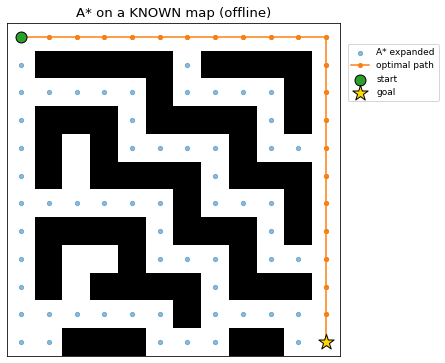

A* optimal path length = 22  |  nodes expanded = 82


In [11]:
# 1 = wall, 0 = free. Robot goes from top-left to bottom-right.
GRID = np.array([
 [0,0,0,0,0,0,0,0,0,0,0,0],[0,1,1,1,1,1,0,1,1,1,1,0],
 [0,0,0,0,0,1,0,0,0,0,1,0],[0,1,1,1,0,1,1,1,1,0,1,0],
 [0,1,0,1,0,0,0,0,1,0,0,0],[0,1,0,1,1,1,1,0,1,1,1,0],
 [0,0,0,0,0,0,1,0,0,0,1,0],[0,1,1,1,1,0,1,1,1,0,1,0],
 [0,1,0,0,1,0,0,0,1,0,0,0],[0,1,0,1,1,1,1,0,1,1,1,0],
 [0,0,0,0,0,0,1,0,0,0,0,0],[0,0,1,1,1,0,0,0,1,1,0,0]])
START, GOALC = (0,0), (11,11); R, C = GRID.shape

def nbrs(s):
    r,c = s
    for dr,dc in ((-1,0),(1,0),(0,-1),(0,1)):
        nr,nc = r+dr, c+dc
        if 0<=nr<R and 0<=nc<C: yield (nr,nc)
def manh(a,b): return abs(a[0]-b[0]) + abs(a[1]-b[1])    # admissible heuristic

def astar(start, goal):
    openh=[(manh(start,goal),0,start)]; came={}; g={start:0}; expanded=set()
    while openh:
        _, gc, s = heapq.heappop(openh)
        if s in expanded: continue
        expanded.add(s)
        if s == goal: break
        for n in nbrs(s):
            if GRID[n]==1: continue
            ng = gc + 1
            if ng < g.get(n, 1e9):
                g[n]=ng; came[n]=s
                heapq.heappush(openh, (ng+manh(n,goal), ng, n))
    path=[goal]
    while path[-1]!=start: path.append(came[path[-1]])
    return path[::-1], expanded

apath, aexp = astar(START, GOALC)

plt.figure(figsize=(6,6))
plt.imshow(GRID, cmap='Greys', origin='upper')
ex = np.array(list(aexp)); plt.scatter(ex[:,1], ex[:,0], c='C0', s=18, alpha=0.5, label='A* expanded')
ap = np.array(apath); plt.plot(ap[:,1], ap[:,0], 'C1-o', ms=4, label='optimal path')
plt.scatter(START[1],START[0], c='C2', s=120, edgecolor='k', zorder=5, label='start')
plt.scatter(GOALC[1],GOALC[0], c='gold', marker='*', s=260, edgecolor='k', zorder=5, label='goal')
plt.legend(loc='upper left', fontsize=9, bbox_to_anchor=(1.01, 0.95)); plt.title('A* on a KNOWN map (offline)')
plt.xticks([]); plt.yticks([]); plt.show()
print(f"A* optimal path length = {len(apath)-1}  |  nodes expanded = {len(aexp)}")



<h3 id="C.2-LRTA*-%E2%80%94-real-time-search-on-an-unknown-map">C.2 LRTA* — real-time search on an <em>unknown</em> map</h3><p>The agent keeps a table $H(s)$ of estimated cost-to-go, initialised to the Manhattan heuristic. At each step it (1) <strong>senses</strong> which of the four neighbors are walls, (2) <strong>updates</strong> the current cell, $H(s)\leftarrow \min_{s'}\,[\,1 + H(s')\,]$, then (3) <strong>moves</strong> to the neighbor minimising $1+H(s')$. Repeatedly revisiting a region raises its $H$, which "fills in" dead ends and pushes the agent out — guaranteeing it eventually reaches the goal in a finite, connected space. <em>(AIMA §4.5.3)</em></p>
<p>We score it with the <strong>competitive ratio</strong>: distance actually travelled ÷ the A* optimum.</p>


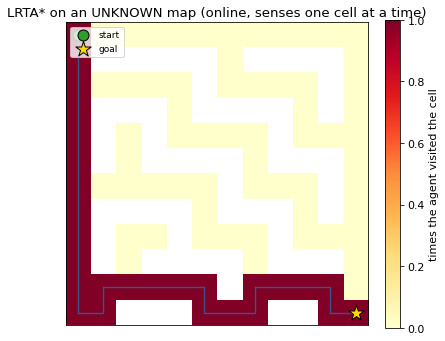

LRTA* reached goal: True
distance travelled = 26   |   A* optimum = 22
competitive ratio  = 1.18  (1.0 would mean it matched the optimal offline path)


In [12]:
def lrta_star(start, goal, max_steps=5000):
    H={}; known_wall=set(); s=start; traj=[s]; visits={s:1}
    h = lambda x: H.get(x, manh(x, goal))
    for _ in range(max_steps):
        if s == goal: break
        for n in nbrs(s):                          # SENSE adjacent cells
            if GRID[n]==1: known_wall.add(n)
        avail = [n for n in nbrs(s) if n not in known_wall]
        if not avail:                              # dead end: retreat
            H[s]=1e9
            if len(traj) > 1: s = traj[-2]; traj.append(s); continue
            break
        H[s] = min(1 + h(n) for n in avail)        # LRTA* update
        s = min(avail, key=lambda n: 1 + h(n))     # move (ties -> first)
        traj.append(s); visits[s] = visits.get(s,0) + 1
    return traj, (s==goal), visits

ltraj, reached, visits = lrta_star(START, GOALC)

vis = np.zeros_like(GRID, float)
for (r,c), k in visits.items(): vis[r,c] = k
vis[GRID==1] = np.nan

plt.figure(figsize=(6,6))
plt.imshow(vis, cmap='YlOrRd', origin='upper')
plt.colorbar(label='times the agent visited the cell', fraction=0.046)
lt = np.array(ltraj); plt.plot(lt[:,1], lt[:,0], 'C0-', lw=1.4, alpha=0.7)
plt.scatter(START[1],START[0], c='C2', s=120, edgecolor='k', zorder=5, label='start')
plt.scatter(GOALC[1],GOALC[0], c='gold', marker='*', s=260, edgecolor='k', zorder=5, label='goal')
plt.legend(loc='upper left', fontsize=9)
plt.title('LRTA* on an UNKNOWN map (online, senses one cell at a time)')
plt.xticks([]); plt.yticks([]); plt.show()

opt = len(apath)-1; travelled = len(ltraj)-1
print(f"LRTA* reached goal: {reached}")
print(f"distance travelled = {travelled}   |   A* optimum = {opt}")
print(f"competitive ratio  = {travelled/opt:.2f}  (1.0 would mean it matched the optimal offline path)")



<h2 id="Summary">Summary</h2><table>
<thead>
<tr>
<th>Method</th>
<th>Knows?</th>
<th>Strength</th>
<th>Failure mode</th>
<th>Reading</th>
</tr>
</thead>
<tbody>
<tr>
<td><strong>Hill climbing</strong></td>
<td>objective at neighbors</td>
<td>tiny memory, fast</td>
<td>local maxima / ridges / plateaus</td>
<td>AIMA §4.1.1</td>
</tr>
<tr>
<td><strong>Simulated annealing</strong></td>
<td>objective &amp; random moves</td>
<td>escapes local optima</td>
<td>needs a good cooling schedule</td>
<td>AIMA §4.1.2</td>
</tr>
<tr>
<td><strong>Gradient descent</strong></td>
<td>$\nabla f$ in continuous space</td>
<td>works where states are infinite</td>
<td>local minima</td>
<td>AIMA §4.2</td>
</tr>
<tr>
<td><strong>Potential fields</strong></td>
<td>local attractive+repulsive forces</td>
<td>reactive, no map, real-time</td>
<td>local-minimum traps</td>
<td>Murphy §8.3</td>
</tr>
<tr>
<td><strong>A*</strong></td>
<td>the whole map</td>
<td>optimal path</td>
<td>needs the full map up front</td>
<td>AIMA §3 / §4.5</td>
</tr>
<tr>
<td><strong>LRTA*</strong></td>
<td>only goal &amp; what it senses</td>
<td>acts in unknown space</td>
<td>longer than optimal (&gt;1 competitive ratio)</td>
<td>AIMA §4.5.3</td>
</tr>
</tbody>
</table>
<h4 id="The-Recurring-Lesson-for-Reactive-Robotics">The Recurring Lesson for Reactive Robotics</h4><p>Acting on purely local information is cheap and fast but every greedy method can get stuck — hill climbing on a peak, a potential field in a dead spot. The escapes (randomisation in annealing, a tangential swirl in potential fields, learned $H$-values in LRTA*) all add a non-greedy ingredient that trades a little efficiency for the ability to get unstuck.</p>



<h2 id="%F0%9F%93%9A-References">📚 References</h2><ol>
<li>Murphy, Robin R. Introduction to AI robotics. MIT press, 2019.</li>
<li>Russell, Stuart J. Artificial intelligence a modern approach. Pearson, 2021.</li>
</ol>
<hr/>
<h2 id="%F0%9F%8F%83-Exercises">🏃 Exercises</h2><p><strong>Exercise 1.</strong> Add a <strong>random-restart</strong> wrapper around <code>hill_climb</code> and measure how many restarts it takes to match simulated annealing.</p>
<p><strong>Exercise 2.</strong> Tune the annealing <code>schedule</code> (<code>T0</code>, <code>alpha</code>): what happens if you cool too fast?</p>
<p><strong>Exercise 3.</strong> Add a third obstacle in Continous Search that creates a new trap; find a <code>tangential</code> value that escapes it.</p>
<p><strong>Exercise 4.</strong> Make the <code>GRID</code> in Online Search bigger or add a one-cell-wide maze, and watch the LRTA* competitive ratio change.</p>
<hr/>


In [13]:
%%html
<style>
    table {margin-left: 0 !important;}
    p {font-family: verdana;}
    li {font-family: verdana;}
    div {font-size: 10pt;}
</style>
<!-- Display markdown tables left oriented in this notebook. -->



<hr/>
<hr/>
